# Import Section

In [2]:



#######################################################################
## Scientific Libraries

import numpy as np
from scipy import stats

import brian2
from brian2 import second, ms, pA, Hz

#######################################################################
## Misc Libraries

import csv,pickle
import os,sys,inspect

from pathlib import Path

currentdir = Path.cwd()
project_root = next(
    (path for path in (currentdir, *currentdir.parents)
     if (path / "simulations" / "multiple_simulations.py").is_file()),
    None,
)
if project_root is None:
    raise RuntimeError(
        f"Cannot locate the atoum project root from {currentdir}. "
        "Start Jupyter from the repository root or its final_notebooks folder."
    )

for module_dir in (project_root, project_root / "simulations", project_root / "toolboxes"):
    sys.path.insert(0, str(module_dir))

#######################################################################
## Cosmetic Libraries

from tqdm.notebook import tqdm

from termcolor import colored

#######################################################################
## Plotting Libraries

import matplotlib.pyplot as plt
import seaborn as sns

import plotly as plty
import plotly.figure_factory as ff
import plotly.graph_objects as go
import plotly.express as px



#####################àà##################################################
## Home Made Libraries




from multiple_simulations import MultipleSimulations

from model_class import Model

from model_toolbox import *

from template_kwargs import template_kwargs

#######################################################################
## Setting font for the figures

font = {'family' : 'normal',
        'size'   : 22}

plt.rc('font', **font)


import warnings
warnings.filterwarnings('ignore')
plt.logging.getLogger('matplotlib.font_manager').disabled = True


import random


random.seed(1)
np.random.seed(1)





# Model definition

## Network Params

In [3]:

network_params = dict(template_kwargs)

network_params

{'tau_r': 2. * msecond,
 'tau_a': 2. * msecond,
 'tau_g': 5. * msecond,
 'tau_n': 60. * msecond,
 'gamma_n': 1.282,
 'gamma_a': 2,
 'gamma_g': 2,
 'c_a': 1. * pamp,
 'c_n': 1. * pamp,
 'a_e': 1.35e+11 * second ** -1 * amp ** -1,
 'b_e': 54. * hertz,
 'd_e': 308. * msecond,
 'g_i': 4.0,
 'c_1': 6.15e+11 * second ** -1 * amp ** -1,
 'c_0': 177. * hertz,
 'r_0': 5.5 * hertz,
 'i_bg_e': 0.3294 * namp,
 'i_bg_i': 260. * pamp,
 'sigma_e': 0. * amp,
 'sigma_i': 0. * amp,
 'active_area': [b'V1'],
 'i_ext': 200. * pamp,
 'stim_on': 10. * msecond,
 'stim_off': 60. * msecond,
 'run_t': 1. * second,
 'dt': 0.5 * msecond,
 'fixed_vars': [],
 'area_number': 40,
 'gN': 1. * namp,
 'gA': 10. * namp,
 'fln_a': 1.2,
 'fln_b': 0.3,
 'connectivity_file': 'subgraph_data40.pkl',
 'spine_count_file': 'spine_count_40_areas.npy',
 'G': 1.5,
 'Gi': 0.105,
 'kappa_loc': 0.90909,
 'g_s': 0.484,
 'g_c': 0,
 'z_min': 0.6,
 'zI_min': 0.218,
 'g_0': 215. * pamp,
 'g_ie': 0.01,
 'j_gei': -8.8 * namp,
 'j_gii': -120. *

In [4]:


network_params = dict(template_kwargs)

network_params['run_t'] = 500*ms
network_params['stim_on'] = 100*ms
network_params['stim_off'] = 150*ms
network_params['sigma_e'] = 5*pA
network_params['sigma_i'] = 5*pA

network_params = get_full_kwargs(network_params)


In [5]:


network_params = dict(template_kwargs)

network_params =get_full_kwargs(network_params)

network_params['run_t'] = 500*ms
network_params['stim_on'] = 100*ms
network_params['stim_off'] = 150*ms
network_params['sigma_e'] = 5*pA
network_params['sigma_i'] = 5*pA


a_e,b_e,d_e = network_params["a_e"],network_params["b_e"],network_params["d_e"]
recording_functions = {
                'firing_rates':{
                'function': (lambda m : m.get_r()),
                'args' : {},
                'type':"at_the_end",
                'data_shape': (int(network_params["run_t"]/network_params["dt"])+1,network_params['area_number']),
            },
                'firing_rates2':{
                'function': (lambda m : m.get_r(2)),
                'args' : {},
                'type':"at_the_end",
                'data_shape': (int(network_params["run_t"]/network_params["dt"])+1,network_params['area_number']),
            },
        }


def launch_simu(network_params,simulation_number=1,talky=False):

    kwargs = {'network_params':dict(network_params),'talky':False}
    recording_step = 1
    simulation_steps= 1
    simulation_number = simulation_number

    mss = MultipleSimulations(Model,recording_functions,object_kwargs=kwargs,recording_step=recording_step,
                             simulation_steps=simulation_steps,simulation_number=simulation_number,talky=talky,
                             )
    mss.run()
    return mss


## Network

## Launching Simulations

In [6]:
#######################################################################
#######################################################################
## Create a MultipleSimulation instance to launch 50 simulations 
## for three different input strength in V1 (Weak, Medium and Strong)
##


#######################################################################
## Multiple Simulations Parameters
kwargs = {'network_params':dict(network_params)}

recording_step = 1 # Not relevent here
simulation_steps = 1 # Not relevent her
simulation_number = 50 # Number 


min_current = 200 # Weak Current value
max_current = 300 # Strong Current value
current_unit = pA
current_number = 3 # Weak, Medium, Strong

mp = {
    'i_ext' : (min_current,max_current,current_number,current_unit),
}


#######################################################################
## Intancing Multiple Simulations Object

multiple_simulations = MultipleSimulations(Model,recording_functions,object_kwargs=kwargs,recording_step=recording_step,
                         simulation_steps=simulation_steps,simulation_number=simulation_number,moving_params=mp)

#######################################################################
## Running the simulations

multiple_simulations.run()



  0%|          | 0/150 [00:00<?, ?it/s]

In [7]:
pfc_area = 23
v1_area = 0


time_axis = multiple_simulations.simulations[0].object.t_plot/ms-network_params["stim_on"]/ms

firing_rates = multiple_simulations.data["firing_rates"]

catch_trials = (firing_rates[:,:,-1,pfc_area]>20)

i_ext = np.linspace(mp["i_ext"][0],mp["i_ext"][1],mp["i_ext"][2])*mp["i_ext"][3]

colors = ['#CBC9E2','#9E9AC8','#6A51A3']

np.mean(catch_trials,1)

array([0.16, 0.48, 0.64])

# Catch Trials

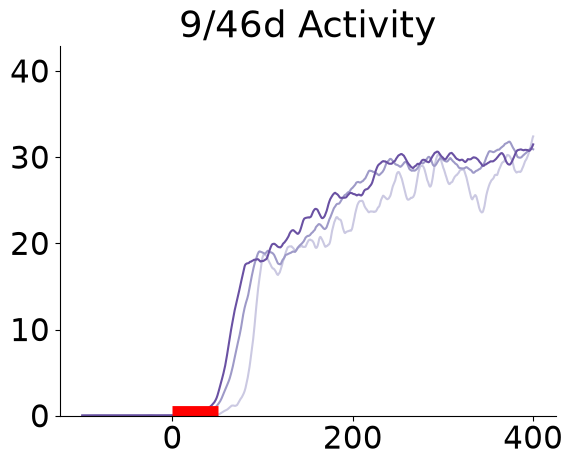

In [8]:
pfc_data = firing_rates[:,:,:,pfc_area]
max_activity_pfc = np.max(pfc_data)

for i in range(current_number):
    plt.plot(time_axis,np.mean(pfc_data[i,:,][catch_trials[i]],0),color=colors[i])
    
plt.ylim([0,max_activity_pfc])

plt.hlines(0, 0, 50,linewidth=15,color="r")
plt.title("9/46d Activity")

plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.show()

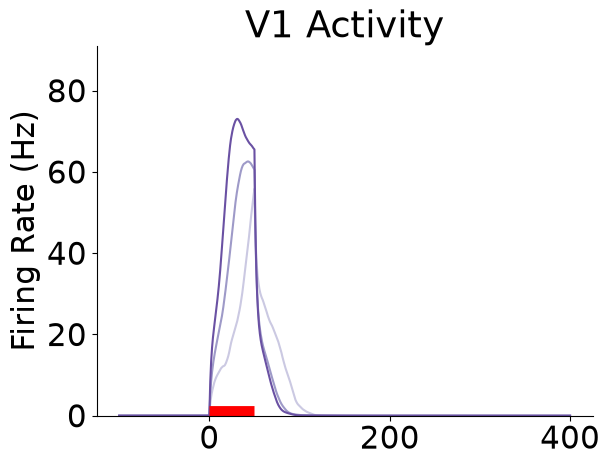

In [9]:
v1_data = firing_rates[:,:,:,v1_area]
max_activity_v1 = np.max(v1_data)

for i in range(3):
    plt.plot(time_axis,np.mean(v1_data[i,:,][catch_trials[i]],0),color=colors[i])
    
plt.ylim([0,max_activity_v1*1.1])
plt.ylabel("Firing Rate (Hz)")

plt.hlines(0, 0, 50,linewidth=15,color="r")
plt.title("V1 Activity")

plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.show()





# Mised Trials

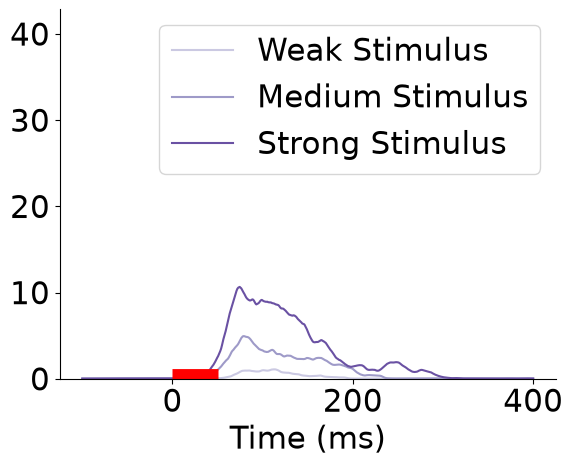

In [10]:
pfc_data = firing_rates[:,:,:,pfc_area]
max_activity_pfc = np.max(pfc_data)

labels=['Weak Stimulus','Medium Stimulus','Strong Stimulus']
for i in range(3):
    plt.plot(time_axis,np.mean(pfc_data[i,:,][np.logical_not(catch_trials[i])],0),
             label=labels[i],color=colors[i])
    
plt.ylim([0,max_activity_pfc])
plt.xlabel("Time (ms)")

plt.hlines(0, 0, 50,linewidth=15,color="r")
plt.legend()
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.show()

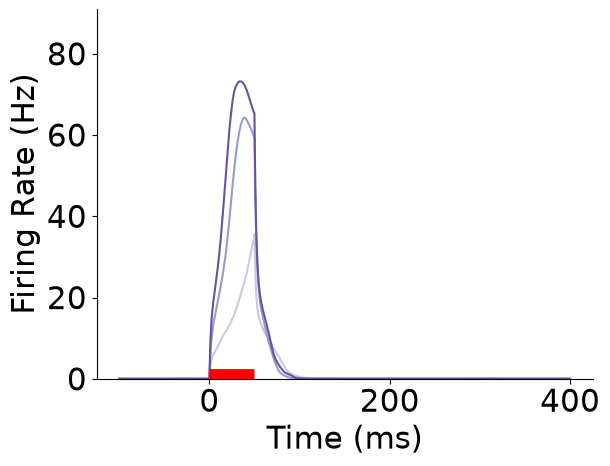

In [11]:
v1_data = firing_rates[:,:,:,v1_area]
max_activity_v1 = np.max(v1_data)


for i in range(3):
    plt.plot(time_axis,np.mean(v1_data[i,:,][np.logical_not(catch_trials[i])],0),color=colors[i])
    
plt.ylim([0,max_activity_v1*1.1])

plt.ylabel("Firing Rate (Hz)")
plt.xlabel("Time (ms)")

plt.hlines(0, 0, 50,linewidth=15,color="r")

plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)


plt.show()

In [12]:

font = {'family' : 'normal',
        'size'   : 22}

plt.rc('font', **font)

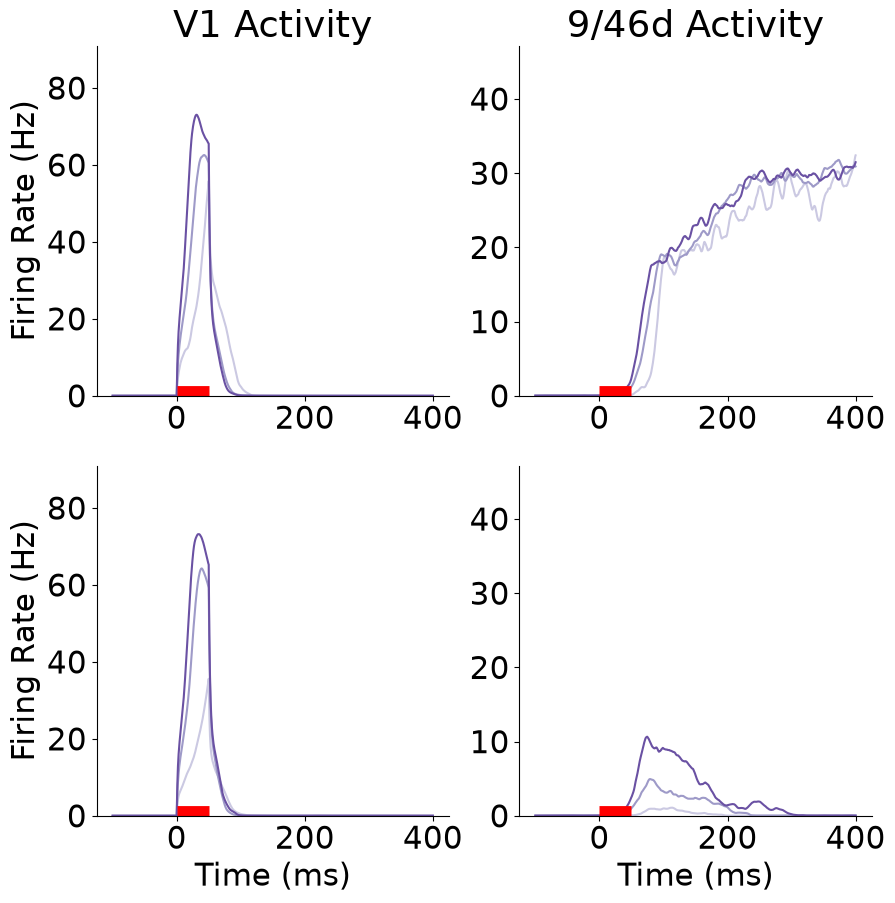

In [13]:

plt.figure(figsize=(10, 10))

plt.subplot(221)


v1_data = firing_rates[:,:,:,v1_area]
max_activity_v1 = np.max(v1_data)

for i in range(3):
    plt.plot(time_axis,np.mean(v1_data[i,:,][catch_trials[i]],0),color=colors[i])
    
plt.ylim([0,max_activity_v1*1.1])
plt.ylabel("Firing Rate (Hz)")

plt.hlines(0, 0, 50,linewidth=15,color="r")
plt.title("V1 Activity")

plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)


plt.subplot(222)

pfc_data = firing_rates[:,:,:,pfc_area]
max_activity_pfc = np.max(pfc_data)

for i in range(current_number):
    plt.plot(time_axis,np.mean(pfc_data[i,:,][catch_trials[i]],0),color=colors[i])
    
plt.ylim([0,max_activity_pfc*1.1])

plt.hlines(0, 0, 50,linewidth=15,color="r")
plt.title("9/46d Activity")

plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.subplot(223)

v1_data = firing_rates[:,:,:,v1_area]
max_activity_v1 = np.max(v1_data)


for i in range(3):
    plt.plot(time_axis,np.mean(v1_data[i,:,][np.logical_not(catch_trials[i])],0),color=colors[i])
    
plt.ylim([0,max_activity_v1*1.1])

plt.ylabel("Firing Rate (Hz)")
plt.xlabel("Time (ms)")

plt.hlines(0, 0, 50,linewidth=15,color="r")

plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)


plt.subplot(224)

pfc_data = firing_rates[:,:,:,pfc_area]
max_activity_pfc = np.max(pfc_data)

labels=['Weak Stimulus','Medium Stimulus','Strong Stimulus']
for i in range(3):
    plt.plot(time_axis,np.mean(pfc_data[i,:,][np.logical_not(catch_trials[i])],0),
             label=labels[i],color=colors[i])
    
plt.ylim([0,max_activity_pfc*1.1])
plt.xlabel("Time (ms)")

plt.hlines(0, 0, 50,linewidth=15,color="r")
#plt.legend()
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.show()

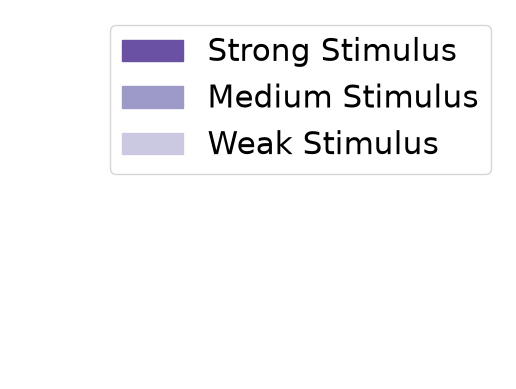

In [14]:
import matplotlib as mpl
# Create a color palette
palette = dict(zip(
    ['Strong Stimulus', 'Medium Stimulus','Weak Stimulus'],
    colors[::-1]))
# Create legend handles manually
handles = [mpl.patches.Patch(color=palette[x], label=x) for x in palette.keys()]
# Create legend
plt.legend(handles=handles)
# Get current axes object and turn off axis
plt.gca().set_axis_off()
plt.show()

# End